# Step 2 – Training & Evaluating the 5 Classifiers

1. drop duplicate rows and make a stratified 80 / 20 train–test split (the 20 % is saved as `test_data.csv` for the Streamlit app),
2. tune each model with 5-fold stratified `GridSearchCV` (scoring = macro F1) on the **training split only**,
3. evaluate the tuned model on the test split and save it to `model/<name>.joblib`.

Each saved model is a scikit-learn `Pipeline`, so any scaling it needs travels with it and the app can feed raw CSV rows straight in.

In [1]:
#!pip install pandas
#!pip install scikit-learn
#!pip install joblib
#!pip install matplotlib

## 1. Setup

In [2]:
import json
import platform
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

print("Python      :", platform.python_version())
print("scikit-learn:", sklearn.__version__)

Python      : 3.12.16
scikit-learn: 1.6.1


In [3]:
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_CSV = PROJECT_DIR / "data" / "Dry_Bean_Dataset.csv"
TEST_CSV = PROJECT_DIR / "test_data.csv"
MODEL_DIR = PROJECT_DIR / "model"
MODEL_DIR.mkdir(exist_ok=True)

TARGET = "Class"
SEED = 42
TEST_SHARE = 0.20

## 2. Load data and create the train / test split

In [4]:
beans = pd.read_csv(RAW_CSV)
n_before = len(beans)
beans = beans.drop_duplicates().reset_index(drop=True)
print(f"Loaded {n_before} rows, dropped {n_before - len(beans)} duplicates -> {len(beans)} rows")

X = beans.drop(columns=TARGET)
y = beans[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SHARE, stratify=y, random_state=SEED
)
print(f"Train: {len(X_train)} rows | Test: {len(X_test)} rows")

# held-out split is what gets uploaded to the Streamlit app
pd.concat([X_test, y_test], axis=1).to_csv(TEST_CSV, index=False)
print("Saved test split ->", TEST_CSV)

Loaded 13611 rows, dropped 68 duplicates -> 13543 rows
Train: 10834 rows | Test: 2709 rows
Saved test split -> /home/s2026ak05252/Downloads/ML_Assignment2/test_data.csv


## 3. Shared helpers
`evaluate` computes the six required metrics. Because there are 7 classes, Precision / Recall / F1 are **macro-averaged** (every bean variety counts equally) and AUC is **one-vs-rest macro**.

In [5]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
results = {}


def evaluate(fitted_model, X_eval, y_eval):
    y_pred = fitted_model.predict(X_eval)
    y_proba = fitted_model.predict_proba(X_eval)
    return {
        "Accuracy": accuracy_score(y_eval, y_pred),
        "AUC": roc_auc_score(y_eval, y_proba, multi_class="ovr", average="macro",
                             labels=fitted_model.classes_),
        "Precision": precision_score(y_eval, y_pred, average="macro", zero_division=0),
        "Recall": recall_score(y_eval, y_pred, average="macro", zero_division=0),
        "F1": f1_score(y_eval, y_pred, average="macro", zero_division=0),
        "MCC": matthews_corrcoef(y_eval, y_pred),
    }


def tune_and_save(key, display_name, pipeline, grid):
    """Grid-search on the training split, score on the test split, save the best pipeline."""
    started = time.time()
    search = GridSearchCV(pipeline, grid, scoring="f1_macro", cv=folds, n_jobs=-1)
    search.fit(X_train, y_train)
    best_model = search.best_estimator_

    joblib.dump(best_model, MODEL_DIR / f"{key}.joblib")
    results[key] = {
        "name": display_name,
        "best_params": {k.replace("clf__", ""): v for k, v in search.best_params_.items()},
        "cv_f1_macro": round(search.best_score_, 4),
        "test_metrics": {m: round(v, 4) for m, v in evaluate(best_model, X_test, y_test).items()},
    }
    print(f"{display_name} tuned in {time.time() - started:.1f}s")
    print("Best params :", results[key]["best_params"])
    print("CV macro F1 :", results[key]["cv_f1_macro"])
    return best_model


def show_model_report(key, fitted_model):
    display(pd.DataFrame([results[key]["test_metrics"]], index=[results[key]["name"]]))
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay.from_estimator(fitted_model, X_test, y_test, ax=ax,
                                          cmap="Greens", colorbar=False, xticks_rotation=45)
    ax.set_title(f"{results[key]['name']} – confusion matrix (test set)")
    plt.tight_layout()
    plt.show()

## 4. Logistic Regression

Linear model on standardised features. `C` is the inverse regularisation strength.

/home/cloud/anaconda3/envs/ML_Assignment2/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/cloud/anaconda3/envs/ML_Assignment2/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/cloud/anaconda3/envs/ML_Assignment2/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/cloud/anaconda3/envs/ML_Assignment2/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/cloud/anaconda3/envs/ML_Assignment2/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/cloud/anaconda3/envs/ML_Assignment2/lib/python3.1

Logistic Regression tuned in 22.4s
Best params : {'C': 500}
CV macro F1 : 0.9378


,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.9177,0.9948,0.9296,0.9296,0.9295,0.9005


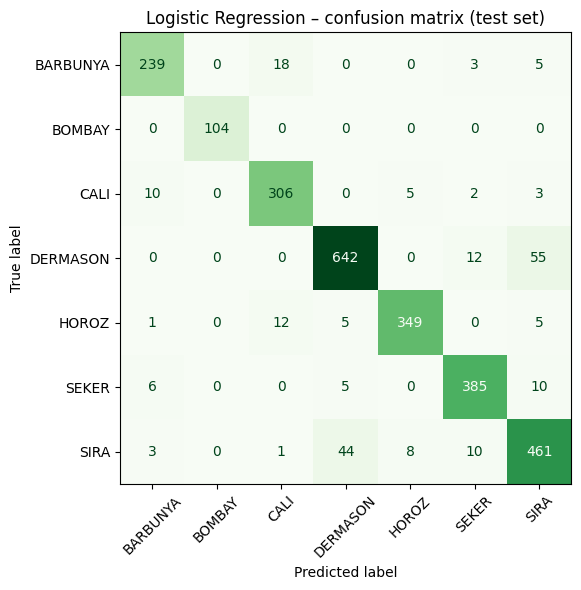

In [6]:
logistic_regression_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("clf", LogisticRegression(max_iter=3000)),
])
logistic_regression_grid = {"clf__C": [1, 10, 100, 500]}

logistic_regression_model = tune_and_save("logistic_regression", "Logistic Regression", logistic_regression_pipeline, logistic_regression_grid)
show_model_report("logistic_regression", logistic_regression_model)

## 5. Decision Tree

Tree splits are threshold-based, so no scaling is needed. Depth and leaf size are tuned to limit overfitting.

Decision Tree tuned in 14.6s
Best params : {'criterion': 'entropy', 'max_depth': 16, 'min_samples_leaf': 10}
CV macro F1 : 0.9255


,Accuracy,AUC,Precision,Recall,F1,MCC
Decision Tree,0.9011,0.974,0.9138,0.9124,0.913,0.8803


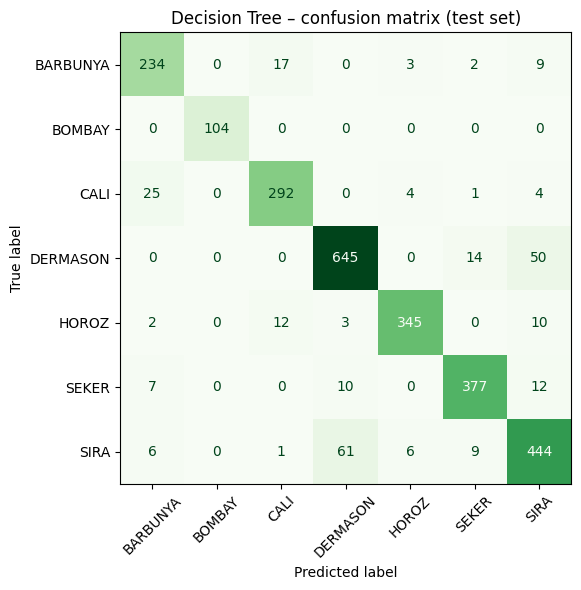

In [7]:
decision_tree_pipeline = Pipeline([
    ("clf", DecisionTreeClassifier(random_state=SEED)),
])
decision_tree_grid = {
    "clf__criterion": ["gini", "entropy"],
    "clf__max_depth": [8, 12, 16, None],
    "clf__min_samples_leaf": [5, 10, 20],
}

decision_tree_model = tune_and_save("decision_tree", "Decision Tree", decision_tree_pipeline, decision_tree_grid)
show_model_report("decision_tree", decision_tree_model)

## 6. KNN

Distance-based, so features must be standardised (otherwise `Area` would dominate every distance).

KNN tuned in 6.2s
Best params : {'n_neighbors': 21, 'weights': 'distance'}
CV macro F1 : 0.9374


,Accuracy,AUC,Precision,Recall,F1,MCC
KNN,0.9192,0.9912,0.9334,0.9294,0.9309,0.9023


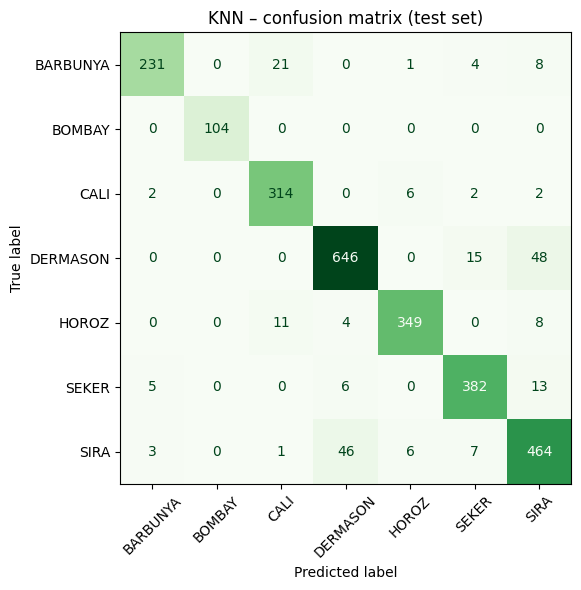

In [8]:
knn_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("clf", KNeighborsClassifier()),
])
knn_grid = {
    "clf__n_neighbors": [9, 15, 21, 31, 41],
    "clf__weights": ["uniform", "distance"],
}

knn_model = tune_and_save("knn", "KNN", knn_pipeline, knn_grid)
show_model_report("knn", knn_model)

## 7. Naive Bayes

Gaussian Naive Bayes (features are continuous). It assumes features are independent given the class(This is an assumption this dataset clearly breaks).

Naive Bayes tuned in 0.5s
Best params : {'var_smoothing': 1e-09}
CV macro F1 : 0.7632


,Accuracy,AUC,Precision,Recall,F1,MCC
Naive Bayes,0.763,0.967,0.7736,0.7685,0.7669,0.7143


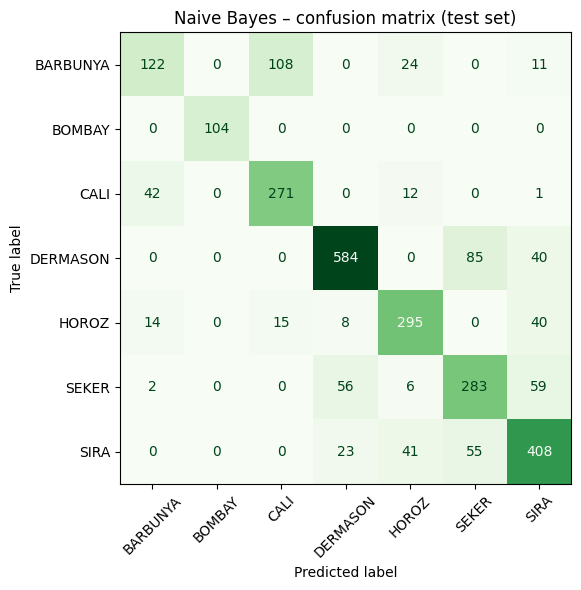

In [9]:
naive_bayes_pipeline = Pipeline([
    ("clf", GaussianNB()),
])
naive_bayes_grid = {"clf__var_smoothing": [1e-9, 1e-7, 1e-5]}

naive_bayes_model = tune_and_save("naive_bayes", "Naive Bayes", naive_bayes_pipeline, naive_bayes_grid)
show_model_report("naive_bayes", naive_bayes_model)

## 8. Support Vector Machine

RBF-kernel SVM on standardised features. `probability=True` is needed so the model can output class probabilities for AUC.

Support Vector Machine tuned in 57.0s
Best params : {'C': 10, 'gamma': 'scale'}
CV macro F1 : 0.9438


,Accuracy,AUC,Precision,Recall,F1,MCC
Support Vector Machine,0.9236,0.9944,0.9356,0.934,0.9347,0.9076


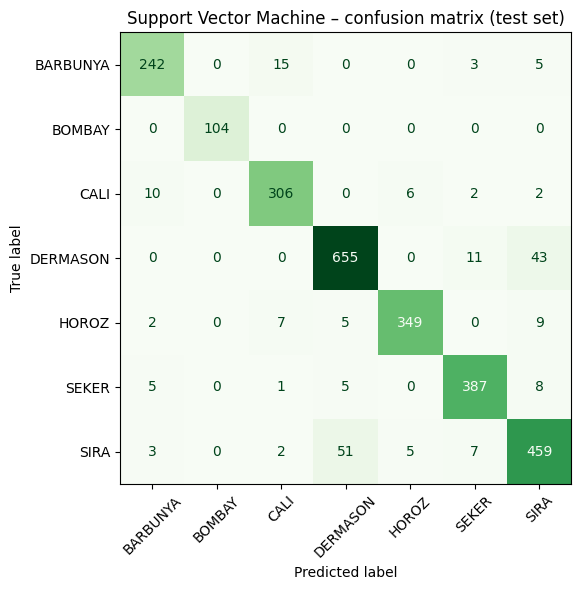

In [10]:
svm_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("clf", SVC(kernel="rbf", probability=True, random_state=SEED)),
])
svm_grid = {"clf__C": [1, 10, 30], "clf__gamma": ["scale", 0.1]}

svm_model = tune_and_save("svm", "Support Vector Machine", svm_pipeline, svm_grid)
show_model_report("svm", svm_model)

## 9. Save metrics and feature info for the Streamlit app
feature_info.json tells the app which columns an uploaded CSV must contain.

In [11]:
with open(MODEL_DIR / "metrics.json", "w") as f:
    json.dump(results, f, indent=2, default=str)

with open(MODEL_DIR / "feature_info.json", "w") as f:
    json.dump({
        "features": list(X.columns),
        "target": TARGET,
        "classes": sorted(y.unique().tolist()),
    }, f, indent=2)

sorted(p.name for p in MODEL_DIR.iterdir())

['decision_tree.joblib',
 'feature_info.json',
 'knn.joblib',
 'logistic_regression.joblib',
 'metrics.json',
 'naive_bayes.joblib',
 'svm.joblib']

## 10. Comparison of all models (test set)

In [12]:
comparison = pd.DataFrame({r["name"]: r["test_metrics"] for r in results.values()}).T
comparison.index.name = "ML Model Name"
comparison.style.format("{:.4f}").highlight_max(color="#c6e5b3")

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9177,0.9948,0.9296,0.9296,0.9295,0.9005
Decision Tree,0.9011,0.9740,0.9138,0.9124,0.9130,0.8803
KNN,0.9192,0.9912,0.9334,0.9294,0.9309,0.9023
Naive Bayes,0.7630,0.9670,0.7736,0.7685,0.7669,0.7143
Support Vector Machine,0.9236,0.9944,0.9356,0.9340,0.9347,0.9076


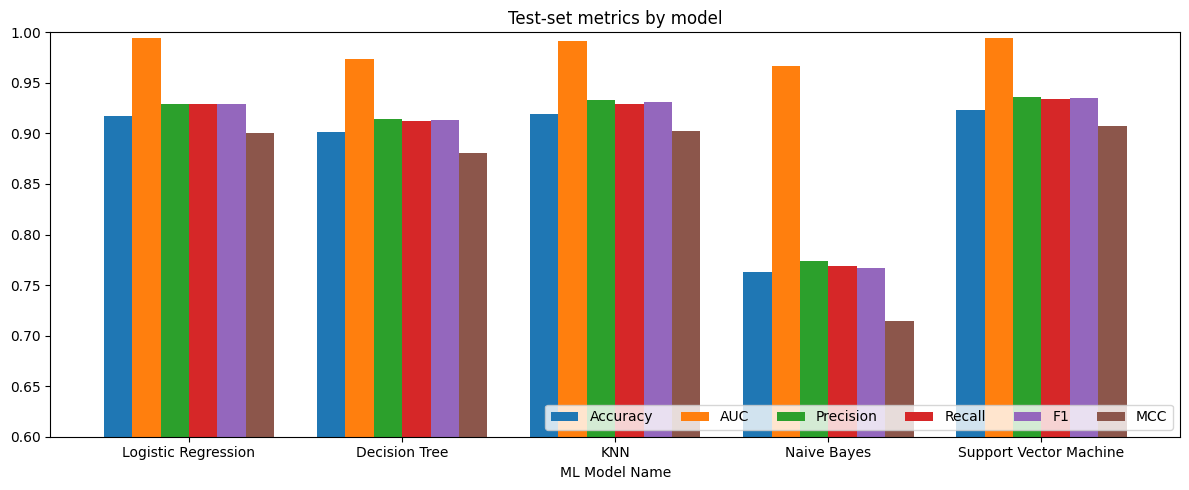

In [13]:
ax = comparison.plot(kind="bar", figsize=(12, 5), ylim=(0.6, 1.0), rot=0, width=0.8)
ax.set_title("Test-set metrics by model")
ax.legend(loc="lower right", ncol=6)
plt.tight_layout()
plt.show()

In [14]:
pd.DataFrame({r["name"]: r["best_params"] for r in results.values()}).T.fillna("–")

,C,criterion,max_depth,min_samples_leaf,n_neighbors,weights,var_smoothing,gamma
Logistic Regression,500.0,–,–,–,–,–,–,–
Decision Tree,–,entropy,16,10,–,–,–,–
KNN,–,–,–,–,21,distance,–,–
Naive Bayes,–,–,–,–,–,–,0.0,–
Support Vector Machine,10,–,–,–,–,–,–,scale


## 11. Observations

| ML Model Name | Observation about model performance |
|---|---|
| Logistic Regression | Strong for a linear model: 91.8% accuracy, MCC 0.90, and the highest AUC (0.9949), so its probability rankings are the best of the five. It chose very weak regularisation (C = 500), meaning the scaled shape features are almost linearly separable. Train and test accuracy are close (93.0% vs 91.8%), so no overfitting. Most errors are DERMASON and SIRA being mistaken for each other. |
| Decision Tree | Lowest of the four strong models: 90.1% accuracy, F1 0.913, MCC 0.880. AUC is lower (0.974) because a tree's leaves give coarse probabilities. It has the largest train/test gap (94.7% vs 90.1%), so it overfits slightly even with max_depth = 16 and min_samples_leaf = 10. Splitting on one feature at a time handles curved class boundaries less well. Weakest on SIRA (recall 0.843). |
| KNN | Close to the best: 91.9% accuracy, F1 0.931, and the best CALI recall (0.963). Best setting: 21 neighbours, with closer neighbours counting more. Training accuracy shows 100% only because, with distance weighting, each training point is its own nearest neighbour; the test score is the honest one. Works well only because features were standardised; otherwise Area would dominate the distances. |
| Naive Bayes | Clearly the worst: 76.3% accuracy, MCC 0.714, and about 3× more errors than the other models (642). It assumes features are independent, but 15 feature pairs are correlated above 0.95, so the same information is counted several times. BARBUNYA recall is only 0.46 (108 BARBUNYA beans were called CALI). AUC is still 0.967, so the right class is often its second-highest guess. Train and test accuracy are equal, so the problem is the model's assumptions, not overfitting. |
| Support Vector Machine | Best on 5 of the 6 metrics: Accuracy 0.9236, Precision 0.9356, Recall 0.9340, F1 0.9347, MCC 0.9076. Its AUC (0.9944) is a close second. It also had the best cross-validation F1 (0.9438) and the fewest test errors (207). The RBF kernel draws curved boundaries, which helps on the hard DERMASON/SIRA pair. Small train/test gap (94.0% vs 92.4%). |
| **Overall winner** | **SVM**, by a small margin over Logistic Regression and KNN (all within 0.6% accuracy). The main difficulty in this dataset is telling DERMASON from SIRA, which every model confuses. BOMBAY is identified almost perfectly by every model because those beans are much larger than the rest. If training speed mattered, Logistic Regression is a close and cheaper alternative with the best AUC. |